# Homework 2: Tokenization

**Course:** NLP Fall 2026  
**Designer:** Faezeh Alinejad

**Name:** Negin Moradi  

In this homework you build the core of a byte-level BPE tokenizer, then use it to study vocabulary size, sequence length and a few Persian quirks (ZWNJ, Arabic letters, digits).


| Component | Points |
|:--|--:|
| TODO 1: `_pair_stats` + `_merge_pair` | 10 |
| TODO 2: `train` | 15 |
| TODO 3: `encode` | 15 |
| TODO 4: `bpe_decode_stream` | 10 |
| TODO 5: `unseen_char_report` | 10 |
| TODO 6: `apply_zwnj_policy` | 5 |
| TODO 7: `analyze_normalization` | 5 |
| Oral questions (4) | 30 |
| **Total** | **100** |


## 0. Setup and corpus
The corpus is a small, deliberately messy Persian and English dataset stored in `notebook1_corpus.json`, next to this notebook. The training text mixes ZWNJ variants, Arabic letter forms (`ي ك`) and Persian or ASCII digits, like real web text. The test sets are clean, but they contain characters and words the tokenizer has never seen (emoji, `é`, `€`).

We work at the **byte level**, so every string can be encoded and there is no `<unk>` token. The price is longer sequences for scripts that need more bytes per character: an English letter is 1 byte in UTF-8, a Persian letter is 2.

In [1]:
import json, os, re, random, difflib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

Z = "\u200c"  # ZWNJ (zero-width non-joiner)

In [2]:
# The corpus lives in notebook1_corpus.json (next to this notebook).
assert os.path.exists(
    "notebook1_corpus.json"
), "notebook1_corpus.json not found: put it next to the notebook (in Colab, upload it in the Files panel)."
with open("notebook1_corpus.json", encoding="utf-8") as f:
    corpus = json.load(f)


def load(split, part):
    return [s.replace("~", Z) for s in corpus[split][part]]


TRAIN_CLEAN = (
    load("train", "fa")
    + load("train", "en")
    + load("train", "mix")
    + load("train", "nums")
)
TEST_FA, TEST_EN, TEST_MIX = load("test", "fa"), load("test", "en"), load("test", "mix")
TEST = TEST_FA + TEST_EN + TEST_MIX

print(
    f"train: {len(TRAIN_CLEAN)} sentences (fa {len(corpus['train']['fa'])}, en {len(corpus['train']['en'])}, "
    f"mixed {len(corpus['train']['mix'])}, numbers {len(corpus['train']['nums'])})"
)
print(
    f"test:  {len(TEST)} sentences (fa {len(TEST_FA)}, en {len(TEST_EN)}, mixed {len(TEST_MIX)})"
)

train: 418 sentences (fa 172, en 144, mixed 68, numbers 34)
test:  90 sentences (fa 30, en 30, mixed 30)


In [3]:
# Real web text is messy, so about 30% of the training lines get a random variant:
# ZWNJ -> space, ZWNJ removed, Arabic letters (ي ك), or Persian digits. The test sets stay clean.
PERTS = ["zwnj_space", "zwnj_remove", "arabic", "digits_fa"]
FA_DIGITS = str.maketrans("0123456789", "۰۱۲۳۴۵۶۷۸۹")


def perturb(text, kind):
    if kind == "zwnj_space":
        return text.replace(Z, " ")
    if kind == "zwnj_remove":
        return text.replace(Z, "")
    if kind == "arabic":
        return text.replace("ی", "ي").replace("ک", "ك")
    if kind == "digits_fa":
        return text.translate(FA_DIGITS)
    raise ValueError(kind)


rng_noise = random.Random(1)


def add_noise(text, p=0.3):
    if rng_noise.random() > p:
        return text
    return perturb(text, rng_noise.choice(PERTS))


TRAIN = [add_noise(t) for t in TRAIN_CLEAN]
rng_noise.shuffle(TRAIN)
print("example train lines:", *TRAIN[:3], sep="\n  ")

example train lines:
  برای شام آش رشته و کمی سبزی خوردن درست کردیم.
  The dataset was split into training and test parts.
  اگر دیر بیایی، قطار رفته است.


## 1. The BPE core: count, merge, train, encode
BPE starts from the 256 byte values and repeatedly merges the **most frequent adjacent pair** into a new symbol. Each merge adds one entry to the vocabulary. You implement three parts, then run the tests below the class.

### TODO 1: count pairs and merge a pair (10 pts)
- `_pair_stats(tokens)` returns `{(a, b): count}` for all adjacent pairs.
- `_merge_pair(pair, tokens)` replaces every adjacent `(a, b)` with the single symbol `a + b`, scanning left to right. Merging `(a, a)` in `a a a` gives `aa a`, not `a aa`.

### TODO 2: the training loop (15 pts)
Repeat: count pairs over all texts, pick the most frequent one (on a tie, the larger tuple wins), merge it everywhere and record it. Stop at the vocabulary budget, or when the best pair appears fewer than `min_freq` times (merging pairs seen once only memorizes the corpus), so the final vocabulary can be smaller than the budget. Store the merges in `self.merges` and `self.ranks[pair] = index`. The index is the priority used by `encode`.

### TODO 3: encode a string (15 pts)
Start from single bytes and keep applying the **earliest-learned** merge (lowest rank) that is present, until none applies. The optional `k` means "use only the first `k` merges". Section 2 needs it.

In [4]:
class BPETokenizer:
    """Byte-level BPE. Starts from the 256 byte values and learns merges on top."""

    def __init__(self, vocab_size=400):
        self.vocab_size_target = vocab_size
        self.merges = []  # ordered by learning time (= priority)
        self.ranks = {}  # pair -> rank (lower = applied first)
        self.b2i = {bytes([i]): i for i in range(256)}  # byte vocab
        self.i2b = {i: b for b, i in self.b2i.items()}
        self.next_id = 256

    # ---------- TODO 1a ----------
    def _pair_stats(self, tokens):
        """Return {(a, b): count} for adjacent pairs in tokens."""

        counts = Counter()
        for left, right in zip(tokens, tokens[1:]):
            counts[(left, right)] += 1
        return dict(counts)

    # ---------- TODO 1b ----------
    def _merge_pair(self, pair, tokens):
        """Replace every adjacent pair by a + b, scanning left to right.
        Merging (a, a) on [a, a, a] gives [aa, a], not [a, aa]."""

        merged = []
        i = 0

        while i < len(tokens):
            if i + 1 < len(tokens) and (tokens[i], tokens[i + 1]) == pair:
                merged.append(tokens[i] + tokens[i + 1])
                i += 2
            else:
                merged.append(tokens[i])
                i += 1

        return merged

    # ---------- TODO 2 ----------
    def train(self, texts, min_freq=2):
        """Stop at vocab_size_target or when no pair reaches min_freq.
        Ties: the larger tuple wins. Fill self.merges, self.ranks[pair] = index,
        and self.b2i / self.i2b / self.next_id. Return self.merges.
        """

        sequences = [list(text.encode("utf-8")) for text in texts]
        # working with byte strings, not integers, so merged symbols are byte strings
        sequences = [[bytes([b]) for b in seq] for seq in sequences]

        self.merges = []
        self.ranks = {}
        self.b2i = {bytes([i]): i for i in range(256)}
        self.i2b = {i: b for b, i in self.b2i.items()}
        self.next_id = 256

        while self.next_id < self.vocab_size_target:
            pair_counts = Counter()
            for tokens in sequences:
                pair_counts.update(self._pair_stats(tokens))

            if not pair_counts:
                break
            # on equal counts, choose the lexicographically larger pair
            best_pair, best_count = max(
                pair_counts.items(), key=lambda item: (item[1], item[0])
            )
            if best_count < min_freq:
                break

            new_symbol = best_pair[0] + best_pair[1]
            self.ranks[best_pair] = len(self.merges)
            self.merges.append(best_pair)
            self.b2i[new_symbol] = self.next_id
            self.i2b[self.next_id] = new_symbol
            self.next_id += 1

            sequences = [
                self._merge_pair(best_pair, tokens) for tokens in sequences
            ]

        return self.merges

    # ---------- TODO 3 ----------
    def encode(self, text, k=None):
        """If k is given, use only merges with rank < k.
        Return a list of ids (from self.b2i).
        """

        tokens = [bytes([b]) for b in text.encode("utf-8")]
        max_rank = len(self.merges) if k is None else max(0, min(k, len(self.merges)))

        while True:
            candidates = [
                (self.ranks[pair], pair)
                for pair in zip(tokens, tokens[1:])
                if pair in self.ranks and self.ranks[pair] < max_rank
            ]
            if not candidates:
                break
            _, best_pair = min(candidates, key=lambda item: item[0])
            tokens = self._merge_pair(best_pair, tokens)

        return [self.b2i[token] for token in tokens]

    def decode(self, ids):
        return b"".join(self.i2b[i] for i in ids).decode("utf-8", errors="replace")

    def vocab_size(self):
        return self.next_id

In [5]:
# --- TODO 1 tests ---
tok1 = BPETokenizer()

stats = tok1._pair_stats([b"l", b"o", b"w", b"l", b"o"])
assert stats[(b"l", b"o")] == 2
assert stats[(b"o", b"w")] == 1
assert stats[(b"w", b"l")] == 1

assert tok1._merge_pair((b"l", b"o"), [b"l", b"o", b"w", b"l", b"o"]) == [
    b"lo",
    b"w",
    b"lo",
]
assert tok1._merge_pair((b"a", b"a"), [b"a", b"a", b"a"]) == [b"aa", b"a"]

print("TODO 1 passed.")

TODO 1 passed.


In [6]:
# --- TODO 2 tests ---
tok2 = BPETokenizer(vocab_size=270)
merges = tok2.train(["hello world hello world hello world"] * 5, min_freq=2)
assert len(merges) > 0
assert tok2.vocab_size() <= 270

tok2b = BPETokenizer(vocab_size=270)
assert (
    tok2b.train(["hello world hello world hello world"] * 5, min_freq=2) == merges
), "train must be deterministic"

assert (
    BPETokenizer(vocab_size=270).train(["x y z"], min_freq=2) == []
)  # nothing repeats, nothing to merge

print(f"TODO 2 passed. Learned {len(merges)} merges. First 5: {merges[:5]}")

TODO 2 passed. Learned 13 merges. First 5: [(b'w', b'o'), (b'wo', b'r'), (b'wor', b'l'), (b'worl', b'd'), (b'o', b' ')]


In [7]:
# --- TODO 3 tests ---
tok3 = BPETokenizer(vocab_size=280)
tok3.train(["hello world hello world"] * 10)

for text in ["hello", "world", "hello world"]:
    assert tok3.decode(tok3.encode(text)) == text, f"round-trip failed for {text!r}"

assert len(tok3.encode("hello")) <= 4, "expected some compression"
assert tok3.decode(tok3.encode("xyzzy")) == "xyzzy", "byte-level means no <unk>"
assert len(tok3.encode("hello", k=0)) == len("hello"), "k=0 means no merges at all"

print("TODO 3 passed.")

TODO 3 passed.


### TODO 4: decode token by token (10 pts)
In a byte-level tokenizer a token can end in the middle of a character. A Persian letter is 2 bytes, an emoji is 4, and merges can even cut across letters. So a model that generates text token by token cannot simply print each token on its own.

Implement `bpe_decode_stream(tok, ids, flush=False)`. It returns one string per token: the text *completed* when that token arrives (`""` if the current character is still incomplete). Incomplete bytes left at the end are dropped, unless `flush=True`: then they are decoded with `errors="replace"` and appended to the last piece.

Two things must hold. For normal text, the pieces joined together equal `tok.decode(ids)` and none of them contains `\ufffd`. With `flush=True`, they equal `tok.decode(ids)` for any list of ids.

Hint: keep a byte buffer. After each token, emit the longest prefix that is valid UTF-8 and keep the rest.

In [8]:
def bpe_decode_stream(tok, ids, flush=False):
    """One string per token: the text completed when that token arrives ("" if the current character
    is still incomplete). Leftover incomplete bytes are dropped, or with flush=True decoded
    (errors="replace") and appended to the last piece."""

    buffer = b""
    pieces = []

    for token_id in ids:
        buffer += tok.i2b[token_id]
        piece = ""

        # decode as much of the buffer as can be emitted now
        while buffer:
            try:
                piece += buffer.decode("utf-8", errors="strict")
                buffer = b""
            except UnicodeDecodeError as exc:
                if exc.reason == "unexpected end of data" and exc.end == len(buffer):
                    # everything before exc.start is valid; the suffix is incomplete
                    piece += buffer[:exc.start].decode("utf-8", errors="strict")
                    buffer = buffer[exc.start:]
                    break
                # there is malformed data, not merely an incomplete final character
                # emit through the malformed byte(s) using the same replacement behavior as BPETokenizer.decode, then continue with the remainder
                piece += buffer[:exc.end].decode("utf-8", errors="replace")
                buffer = buffer[exc.end:]

        pieces.append(piece)

    if flush and buffer and pieces: # handle leftover bytes when flush=True
        pieces[-1] += buffer.decode("utf-8", errors="replace")

    return pieces

In [9]:
# --- TODO 4 tests ---
raw = BPETokenizer(vocab_size=256)  # no merges: one token per byte
ids = raw.encode("می🙂")  # 2 + 2 + 4 bytes
assert bpe_decode_stream(raw, ids) == ["", "م", "", "ی", "", "", "", "🙂"]
assert bpe_decode_stream(raw, raw.encode("ی")[:1]) == [""], "an incomplete character is not emitted"
assert bpe_decode_stream(raw, raw.encode("ی")[:1], flush=True) == ["\ufffd"], "flush=True emits what is left"

text = "می‌روم و می‌آیم 🙂"
tok4 = BPETokenizer(vocab_size=300)
tok4.train([text] * 20)
ids = tok4.encode(text)
pieces = bpe_decode_stream(tok4, ids)
assert len(pieces) == len(ids)
assert "".join(pieces) == text == tok4.decode(ids)
assert all("\ufffd" not in p for p in pieces)

# with flush=True the pieces always add up to tok.decode, even for arbitrary (invalid) bytes
rng = random.Random(0)
junk = [rng.randrange(256) for _ in range(200)]
assert "".join(bpe_decode_stream(raw, junk, flush=True)) == raw.decode(junk)

print("TODO 4 passed.")

TODO 4 passed.


Now train on the whole corpus (budget 1000) and look at how a few words get split. The last example contains characters the corpus never had.

In [10]:
demo = BPETokenizer(vocab_size=1000)
demo.train(TRAIN)

for text in ["models", "vocabulary", "tokenizer", "unbelievably", "Hello 你好 🙂"]:
    ids = demo.encode(text)
    print(f"{text!r:16} -> {len(ids):2d} tokens  {[demo.i2b[i] for i in ids]}")
    assert demo.decode(ids) == text

'models'         ->  2 tokens  [b'model', b's']
'vocabulary'     ->  2 tokens  [b'vocabular', b'y']
'tokenizer'      ->  4 tokens  [b'to', b'ken', b'iz', b'er']
'unbelievably'   ->  8 tokens  [b'un', b'b', b'el', b'ie', b'v', b'ab', b'l', b'y']
'Hello 你好 🙂'     -> 16 tokens  [b'H', b'e', b'll', b'o', b' ', b'\xe4', b'\xbd', b'\xa0', b'\xe5', b'\xa5', b'\xbd', b' ', b'\xf0', b'\x9f', b'\x99', b'\x82']


### TODO 5: characters the corpus never saw (10 pts)
There is no `<unk>`, but unseen characters may require several byte tokens. Learned byte merges can sometimes reduce this count.

Implement `unseen_char_report(tok, train_texts, test_texts)`. Go over every non-whitespace character of `test_texts`. A character is *seen* if it occurs in `train_texts`, otherwise *unseen*. Encode each character on its own with `tok.encode` to get its cost. Return a dict with:
- `"unseen"`: sorted list of the distinct unseen characters
- `"unk_rate"`: share of test characters that are unseen (what a character-level tokenizer with `<unk>` would lose)
- `"tokens_per_seen_char"` and `"tokens_per_unseen_char"`: mean tokens per character in each group (`0.0` if the group is empty)

In [11]:
def unseen_char_report(tok, train_texts, test_texts):
    """See the description above. Return a dict with the keys
    "unseen", "unk_rate", "tokens_per_seen_char", "tokens_per_unseen_char"."""

    seen_chars = {
        char
        for text in train_texts
        for char in text
        if not char.isspace()
    }
    test_chars = [
        char
        for text in test_texts
        for char in text
        if not char.isspace()
    ]

    unseen_chars = sorted({char for char in test_chars if char not in seen_chars})
    seen_costs = [len(tok.encode(char)) for char in test_chars if char in seen_chars]
    unseen_costs = [len(tok.encode(char)) for char in test_chars if char not in seen_chars]

    total = len(test_chars)
    return {
        "unseen": unseen_chars,
        "unk_rate": (
            sum(char not in seen_chars for char in test_chars) / total
            if total else 0.0
        ),
        "tokens_per_seen_char": float(np.mean(seen_costs)) if seen_costs else 0.0,
        "tokens_per_unseen_char": float(np.mean(unseen_costs)) if unseen_costs else 0.0,
    }

In [12]:
# --- TODO 5 tests ---
tok5 = BPETokenizer(vocab_size=280)
tok5.train(["hello world"] * 10)

r = unseen_char_report(tok5, ["hello world"], ["hello 你好"])
assert r["unseen"] == ["你", "好"]
assert abs(r["unk_rate"] - 2 / 7) < 1e-9
assert r["tokens_per_unseen_char"] == 3, "an unseen CJK character is 3 raw bytes"
assert r["tokens_per_seen_char"] == 1
assert unseen_char_report(tok5, ["abc"], ["abc"])["tokens_per_unseen_char"] == 0.0

print("TODO 5 passed.")

TODO 5 passed.


In [13]:
for name, texts in [("Persian", TEST_FA), ("English", TEST_EN), ("Mixed", TEST_MIX)]:
    r = unseen_char_report(demo, TRAIN, texts)
    print(
        f"{name:8} unseen: {' '.join(r['unseen']) or '-':12} unk_rate (char-level) = {r['unk_rate']:.2%}   "
        f"tokens/char: seen {r['tokens_per_seen_char']:.2f}, unseen {r['tokens_per_unseen_char']:.2f}"
    )

Persian  unseen: -            unk_rate (char-level) = 0.00%   tokens/char: seen 1.01, unseen 0.00
English  unseen: $ : é ï €    unk_rate (char-level) = 0.51%   tokens/char: seen 1.00, unseen 1.86
Mixed    unseen: $ 😅 🙂        unk_rate (char-level) = 0.27%   tokens/char: seen 1.01, unseen 3.00


## 2. Vocabulary size, sequence length and cost
Using only the first k merges gives exactly the tokenizer you would get by training with k merges. So the `demo` tokenizer (budget 1000) already gives the whole curve.

More merges mean fewer tokens per word, which makes attention cheaper (its cost grows with the square of the length). The price is a bigger embedding table and rarer, under-trained tokens. Persian starts much longer (2 bytes per letter), so it gains more from the first merges. That imbalance is one reason multilingual tokenizers are hard to design.

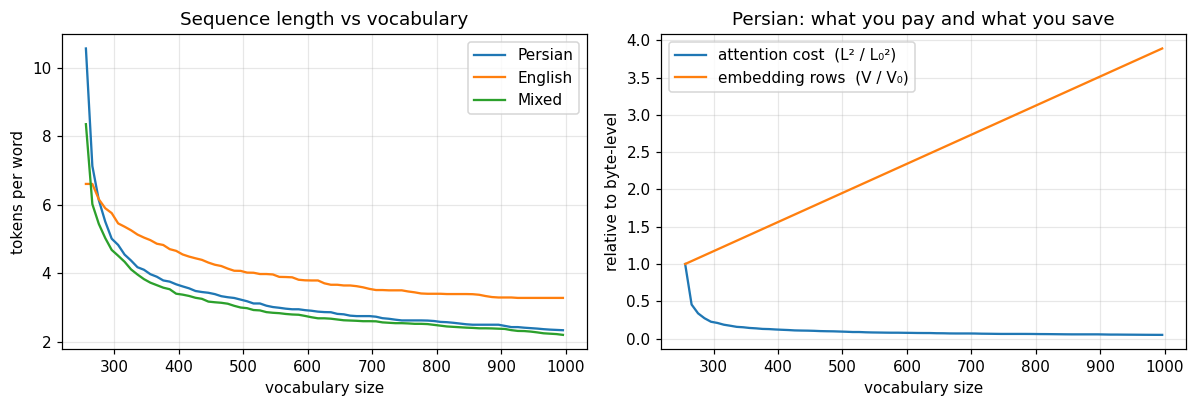

In [14]:
def tokens_per_word(tok, texts, k=None):
    """Average number of tokens per whitespace-separated word (also called fertility)."""
    n_tokens = sum(len(tok.encode(t, k=k)) for t in texts)
    n_words = sum(len(t.split()) for t in texts)
    return n_tokens / n_words


test_sets = {"Persian": TEST_FA, "English": TEST_EN, "Mixed": TEST_MIX}
ks = list(range(0, len(demo.merges) + 1, 10))
vocab_sizes = [256 + k for k in ks]
curves = {
    lang: [tokens_per_word(demo, texts, k) for k in ks]
    for lang, texts in test_sets.items()
}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for lang, ys in curves.items():
    ax[0].plot(vocab_sizes, ys, label=lang)
ax[0].set(
    xlabel="vocabulary size",
    ylabel="tokens per word",
    title="Sequence length vs vocabulary",
)
ax[0].legend()

persian_len = np.array(curves["Persian"]) / curves["Persian"][0]
ax[1].plot(vocab_sizes, persian_len**2, label="attention cost  (L² / L₀²)")
ax[1].plot(vocab_sizes, np.array(vocab_sizes) / 256, label="embedding rows  (V / V₀)")
ax[1].set(
    xlabel="vocabulary size",
    ylabel="relative to byte-level",
    title="Persian: what you pay and what you save",
)
ax[1].legend()
plt.tight_layout()
plt.show()

In [15]:
rows = []
for budget in [256, 300, 400, 600, 800, demo.vocab_size()]:
    k = budget - 256
    rows.append(
        {
            "budget": budget,
            **{
                f"{lang} tok/word": round(tokens_per_word(demo, texts, k), 2)
                for lang, texts in test_sets.items()
            },
        }
    )
display(pd.DataFrame(rows).set_index("budget"))

,Persian tok/word,English tok/word,Mixed tok/word
budget,,,
256,10.55,6.61,8.35
300,4.92,5.63,4.63
400,3.65,4.60,3.39
600,2.92,3.80,2.75
800,2.60,3.41,2.48
1000,2.34,3.29,2.21


## 3. Persian specifics: the ZWNJ policy
The same Persian word can be written `می‌روم` (ZWNJ), `می روم` (space) or `میروم` (nothing). To the tokenizer these are three different inputs. There are three ways to handle them:

- `keep`: the ZWNJ stays (repeated ones are collapsed, and ones next to whitespace are dropped). This preserves the word structure, but every ZWNJ costs 3 bytes.
- `space`: the ZWNJ becomes a space, so one word becomes two.
- `remove`: the ZWNJ is deleted, so `می‌روم` and `میروم` become the same string. This loses information.

### TODO 6: ZWNJ policy (5 pts)
Implement `apply_zwnj_policy(text, policy)` for the three policies. `compare_zwnj_policies` is given: it counts the distinct whitespace-separated word types after `normalize` and the policy.

`normalize` (given) maps Arabic letters to Persian ones, Persian and Arabic-Indic digits to ASCII, and collapses whitespace.

In [16]:
def normalize(text):
    """GIVEN. Arabic letters -> Persian, Persian/Arabic-Indic digits -> ASCII, collapse whitespace.
    ZWNJ is left untouched (that is the job of the ZWNJ policy)."""
    text = text.translate(str.maketrans("يكى", "یکی"))
    text = text.translate(str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789"))
    return re.sub(r"\s+", " ", text).strip()

In [17]:
def apply_zwnj_policy(text, policy):
    """policy in {"keep", "space", "remove"}:
    keep   -> repeated ZWNJs collapse into one; ZWNJ next to whitespace is dropped
    space  -> ZWNJ becomes a space
    remove -> ZWNJ is deleted
    """

    # (?<=\s) checks whether whitespace is immediately before the ZWNJ
    # (?=\s) checks whether whitespace is immediately after the ZWNJ
    if policy == "keep":
        text = re.sub(r"\u200c+", Z, text) # collapses consecutive ZWNJ characters into one
        text = re.sub(r"(?<=\s)\u200c|\u200c(?=\s)", "", text) # removes ZWNJs immediately next to whitespace
        return text
    if policy == "space":
        return text.replace(Z, " ")
    if policy == "remove":
        return text.replace(Z, "")
    raise ValueError("policy must be 'keep', 'space', or 'remove'")

In [18]:
def compare_zwnj_policies(texts, policies=("keep", "space", "remove")):
    """GIVEN. Return {policy: number of distinct word types after normalize + apply_zwnj_policy}."""
    return {
        p: len({w for t in texts for w in apply_zwnj_policy(normalize(t), p).split()})
        for p in policies
    }

In [19]:
# --- TODO 6 tests ---
assert apply_zwnj_policy("می\u200cروم", "space") == "می روم"
assert apply_zwnj_policy("می\u200cروم", "remove") == "میروم"
assert apply_zwnj_policy("می\u200cروم", "keep") == "می\u200cروم"
assert apply_zwnj_policy("می\u200c\u200cروم", "keep") == "می\u200cروم"
assert apply_zwnj_policy("کتاب \u200cها", "keep") == "کتاب ها"

assert compare_zwnj_policies(["کتاب\u200cها"]) == {"keep": 1, "space": 2, "remove": 1}

types = compare_zwnj_policies(["کتاب\u200cها", "کتاب ها", "کتابها"])
assert types["keep"] > types["space"]
assert types["keep"] > types["remove"]

print(f"TODO 6 passed. {types}")

TODO 6 passed. {'keep': 4, 'space': 3, 'remove': 3}


Now the same count on the real, noisy training text. The gaps are small because most lines are unperturbed. `space` has the fewest types because it cuts compounds into short, repeated pieces.

In [20]:
print("distinct word types in TRAIN:", compare_zwnj_policies(TRAIN))

distinct word types in TRAIN: {'keep': 1658, 'space': 1613, 'remove': 1653}


In [21]:
def preprocess(text, zwnj_policy):
    """normalize + ZWNJ policy. With policy None we do no preprocessing except whitespace cleanup."""
    if zwnj_policy is None:
        return re.sub(r"\s+", " ", text).strip()
    return apply_zwnj_policy(normalize(text), zwnj_policy)


class WrappedTokenizer:
    """A BPETokenizer that preprocesses every text before training/encoding."""

    def __init__(self, zwnj_policy=None, budget=400):
        self.zwnj_policy = zwnj_policy
        self.bpe = BPETokenizer(vocab_size=budget)

    def fit(self, texts):
        self.bpe.train([preprocess(t, self.zwnj_policy) for t in texts])
        return self

    def encode(self, text, k=None):
        return self.bpe.encode(preprocess(text, self.zwnj_policy), k=k)

    @property
    def vocab_size(self):
        return self.bpe.vocab_size()


def stability(tok, texts, kind):
    """Mean similarity between the tokens of a text and of its perturbed version (1.0 = identical)."""
    sims = []
    for t in texts:
        p = perturb(t, kind)
        if p != t:
            sims.append(
                difflib.SequenceMatcher(
                    None, tok.encode(t), tok.encode(p), autojunk=False
                ).ratio()
            )
    return float(np.mean(sims)) if sims else 1.0


def run_config(zwnj_policy, budget=400):
    """Train under one preprocessing option and return its metrics as a dict."""
    tok = WrappedTokenizer(zwnj_policy, budget).fit(TRAIN)
    row = dict(
        vocab_size=tok.vocab_size,
        fertility=tokens_per_word(tok, TEST),
        fert_fa=tokens_per_word(tok, TEST_FA),
        fert_mix=tokens_per_word(tok, TEST_MIX),
    )
    for kind in PERTS:
        row["stab_" + kind] = stability(tok, TEST, kind)
    row["stability"] = float(np.mean([row["stab_" + kind] for kind in PERTS]))
    return row

,vocab_size,fertility,fert_fa,fert_mix,stability
None,400,3.870,3.654,3.387,0.874
keep,400,3.835,3.610,3.349,0.960
space,400,3.773,3.511,3.307,0.979
remove,400,3.777,3.489,3.295,0.976


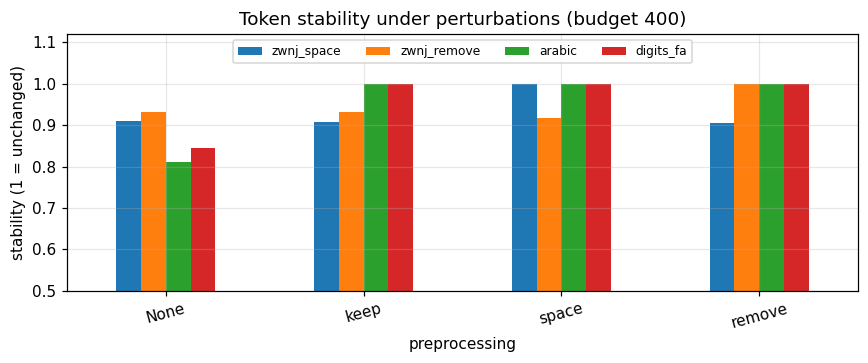

In [22]:
policies = [None, "keep", "space", "remove"]
results = pd.DataFrame(
    [run_config(p) for p in policies], index=[str(p) for p in policies]
)
display(
    results[["vocab_size", "fertility", "fert_fa", "fert_mix", "stability"]].round(3)
)

fig, ax = plt.subplots(figsize=(8, 3.4))
results[[f"stab_{k}" for k in PERTS]].rename(columns=lambda c: c[5:]).plot.bar(
    ax=ax, rot=15, ylim=(0.5, 1.12)
)
ax.legend(ncol=4, loc="upper center", fontsize=8)
ax.set(
    ylabel="stability (1 = unchanged)",
    xlabel="preprocessing",
    title="Token stability under perturbations (budget 400)",
)
plt.tight_layout()
plt.show()

### TODO 7: does normalization help? (5 pts)
Is `normalize` worth it? Implement `analyze_normalization(budget=400)`, which runs `run_config` twice and compares the results.

- `with_norm`: `run_config("keep", budget)`. This is `normalize` plus the mildest ZWNJ policy, so the difference is mostly due to `normalize`.
- `without_norm`: `run_config(None, budget)`. Raw text, only whitespace cleanup.

Return a dict with `"with_norm"` and `"without_norm"` (each holding that run's `fertility` and `stability`) and `"delta_stability"`, the stability with normalize minus the stability without it.

In [23]:
def analyze_normalization(budget=400):
    """Compare run_config("keep", budget) (normalize + keep) with run_config(None, budget) (raw text).
    Return {"with_norm": {"fertility": ..., "stability": ...},
            "without_norm": {"fertility": ..., "stability": ...},
            "delta_stability": with_norm stability - without_norm stability}."""

    with_norm_run = run_config("keep", budget)
    without_norm_run = run_config(None, budget)

    with_norm = {
        "fertility": with_norm_run["fertility"],
        "stability": with_norm_run["stability"],
    }
    without_norm = {
        "fertility": without_norm_run["fertility"],
        "stability": without_norm_run["stability"],
    }

    return {
        "with_norm": with_norm,
        "without_norm": without_norm,
        "delta_stability": with_norm["stability"] - without_norm["stability"],
    }


In [24]:
# --- TODO 7 tests ---
r = analyze_normalization()
assert set(r) == {"with_norm", "without_norm", "delta_stability"}
assert set(r["with_norm"]) == {"fertility", "stability"} == set(r["without_norm"])

# the two runs must be the same experiments as in the table above
assert abs(r["with_norm"]["stability"] - results.loc["keep", "stability"]) < 1e-9
assert abs(r["without_norm"]["fertility"] - results.loc["None", "fertility"]) < 1e-9
assert abs(r["delta_stability"] - (r["with_norm"]["stability"] - r["without_norm"]["stability"])) < 1e-12
assert r["delta_stability"] > 0, "normalize should make the tokens more stable"

print("TODO 7 passed.")


TODO 7 passed.


In [25]:
r = analyze_normalization()
for name in ["with_norm", "without_norm"]:
    print(f"{name:13} fertility = {r[name]['fertility']:.3f}   stability = {r[name]['stability']:.3f}")
print(f"delta_stability = {r['delta_stability']:+.3f}")


with_norm     fertility = 3.835   stability = 0.960
without_norm  fertility = 3.870   stability = 0.874
delta_stability = +0.085
